In [11]:
%pylab inline

import gc
import os
import pltutil
import catutil
import treecorr
import numpy as np
import astropy.io.ascii as ascii
import astropy.io.fits as pyfits
import astropy.table as astTable
import matplotlib.pylab as plt
import matplotlib.lines as mlines

def get_rho_all(_cat):
    if False:
        sstar= catutil.get_sdss_size(_cat,'det')
        spsf = catutil.get_psf_size(_cat,'det')
        fdt = -(spsf-sstar)/sstar
    else:
        sstar=catutil.get_sdss_size(_cat,'trace')**2.
        spsf= catutil.get_psf_size(_cat,'trace')**2.
        fdt = -(spsf-sstar)/sstar
        
    g1Star,g2Star=catutil.get_sdss_ellip(_cat,return_shear=True)
    g1PSF,g2PSF=catutil.get_psf_ellip(_cat,return_shear=True)
    dg1=   g1Star-g1PSF
    dg2=   g2Star-g2PSF
    ra,dec=catutil.get_radec(_cat)
    return {'ra':ra,'dec':dec,'g1p':g1PSF,'g2p':g2PSF,'dg1':dg1,'dg2':dg2,'fdt':fdt}

if False:
    def plotGG(_ax,_ra,_dec,_g1,_g2,_cc,_g1B=None,_g2B=None):
        cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.7,sep_units='degree')
        catT1=   treecorr.Catalog(g1=_g1,g2=-_g2,\
                                    ra=_ra,dec=_dec,\
                                    ra_units='deg',dec_units='deg') 
        if _g1B is None:
            cor.process(catT1,catT1)
        else:
            catTB=   treecorr.Catalog(g1=_g1B,g2=-_g2B,\
                        ra=_ra,dec=_dec,\
                        ra_units='deg',dec_units='deg') 
            cor.process(catT1,catTB)

        msk=cor.xip>0
        xrr=cor.rnom.copy()*60.
        #xrr[~msk]=0.
        xxp=cor.xip.copy()
        xxp[~msk]=0.
        xxv=np.sqrt(cor.varxi.copy()/2.)
        xxv[~msk]=0.
        _ax.errorbar(xrr,xxp,xxv,fmt='-o',\
                    color=_cc,ms=6,elinewidth=1.5,capsize=4,capthick=0.,linewidth=2.)
        nnn=np.sum(msk)
        print(nnn)
        if nnn<20:
            xrr=cor.rnom.copy()*60.
            #xrr[msk]=0.
            xxp=cor.xip.copy()
            xxp[msk]=0.
            xxv=np.sqrt(cor.varxi.copy()/2.)
            xxv[msk]=0.
            _ax.errorbar(xrr,-xxp,xxv,fmt=':s',\
                        color=_cc,ms=6,elinewidth=1.5,capsize=4,capthick=0.,linewidth=2.)

        cor.clear()
        return
else:
    def plotGG(_ax,_ra,_dec,_g1,_g2,_cc,_g1B=None,_g2B=None,weights=None):
        cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.7,sep_units='degree')
        catT1=   treecorr.Catalog(g1=_g1,g2=-_g2,\
                                    ra=_ra,dec=_dec,\
                                    ra_units='deg',dec_units='deg',w=weights) 
        if _g1B is None:
            cor.process(catT1,catT1)
        else:
            catTB=   treecorr.Catalog(g1=_g1B,g2=-_g2B,\
                        ra=_ra,dec=_dec,\
                        ra_units='deg',dec_units='deg',w=weights) 
            cor.process(catT1,catTB)

        msk=cor.xip>0
        xrr=cor.rnom.copy()[msk]*60.
        xxp=cor.xip.copy()[msk]
        xxv=np.sqrt(cor.varxi.copy()/2.)[msk]
        _ax.errorbar(xrr,xxp,xxv,fmt='x',\
                    color=_cc,ms=6,elinewidth=1.5,capsize=0,capthick=0.,linewidth=1.)
        nnn=np.sum(msk)
        print(nnn)
        if nnn<20:
            xrr=cor.rnom.copy()[~msk]*60.
            xxp=cor.xip.copy()[~msk]
            xxv=np.sqrt(cor.varxi.copy()/2.)[~msk]
            _ax.errorbar(xrr,-xxp,xxv,fmt='s',\
                        color=_cc,ms=6,elinewidth=1.5,capsize=0,capthick=0.,linewidth=1.)

        cor.clear()
        return


Populating the interactive namespace from numpy and matplotlib


/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/IPython/core/magics/pylab.py:160: UserWarning: pylab import has clobbered these variables: ['plt']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"


In [12]:
datDir='wrkDir/s19/s19-pre/psf_test_from_wentao/rhoTest/'
datDirR='wrkDir/s19/s19-pre/psf_test_from_wentao/rhoTest2/'
datDir2='wrkDir/s19/s19-pre/psf_test_from_wentao/results/'
pltDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/psfTest/'
fc2='#747778'
fc1='#cbd2d6'
req=ascii.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=req['rr'];rho134n=req['rho134'];rho25n=req['rho25']

In [13]:
if True:
    # determine pend
    pend='fdcut'#-bdcut2'#-bdcut3'
    allname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_star.fits'
    elinpname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_nonpsfstars.fits'
    cat1=pyfits.getdata(allname)
    cat2=pyfits.getdata(elinpname)
    hpfname =   "s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
    hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
    if 'fdcut' in pend:
        maskP1=catutil.get_FDFC_flag(cat1,hpfname=hpfname)
        maskP2=catutil.get_FDFC_flag(cat2,hpfname=hpfname)
        if 'bdcut' in pend:
            cut=eval(pend.split('bdcut')[-1])
            maskP1=maskP1&(np.log10(cat1['i_blendedness_abs'])<-cut)
            maskP2=maskP2&(np.log10(cat2['i_blendedness_abs'])<-cut)
    else:
        maskP1=np.ones(len(cat1),dtype=bool)
        maskP2=np.ones(len(cat2),dtype=bool)

    cat3=cat1[~cat1['i_calib_psf_used']&maskP1]
    cat1=cat1[cat1['i_calib_psf_used']&maskP1]
    cat2=cat2[maskP2]
else:
    pend='s16a'
    dataAll=[]
    for fieldname in catutil.field_names:
        fname='/work/xiangchong.li/work/galSim-HSC/database/s16/S16AStandardV2/field/%s_stars.fits'  %(fieldname)
        data=astTable.Table.read(fname)
        dataAll.append(data)
        del data
        gc.collect()
    cat=astTable.vstack(dataAll)
    cat1=cat[cat['icalib_psf_used']]
    cat2=cat[~cat['icalib_psf_used']]

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


Text(0.5, 0, 'FWHM [arcsec]')

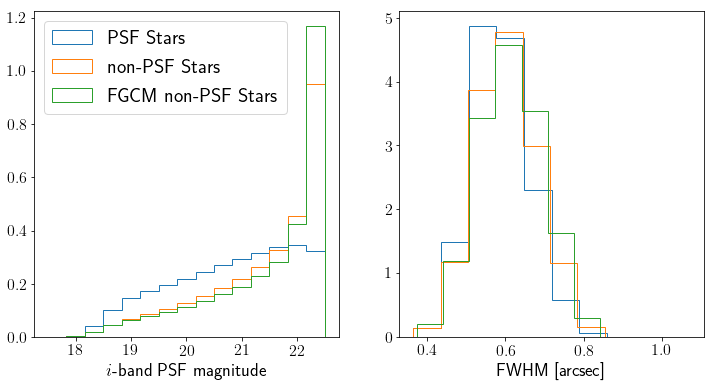

In [14]:
w2=None
plt.close()
fig=plt.figure(figsize=(12,6))
ax=fig.add_subplot(1,2,1)
hist1,bb,_xx=ax.hist(cat1['i_psfflux_mag'],label='PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step')
ax.hist(cat3['i_psfflux_mag'],label='non-PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step')
hist2,bb,_xx=ax.hist(cat2['i_psfflux_mag'],label='FGCM non-PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step',weights=w2)
ax.legend(loc='upper left')
ax.set_xlabel(r'$i$-band PSF magnitude')
ax=fig.add_subplot(1,2,2)
ax.hist(catutil.get_psf_size(cat1),label='PSF Stars',density=True,histtype='step')
ax.hist(catutil.get_psf_size(cat3),label='non-PSF Stars',density=True,histtype='step')
ax.hist(catutil.get_psf_size(cat2),label='FGCM non-PSF Stars',density=True,histtype='step')
ax.set_xlabel('FWHM [arcsec]')

In [15]:
w2_tmp=hist1/hist2
w2=w2_tmp[np.digitize(cat2['i_psfflux_mag'],bins=bb)-1]

In [16]:
rhoA=get_rho_all(cat1)
rhoB=get_rho_all(cat2)

20
18
20
11
20
18
5
16
0
0


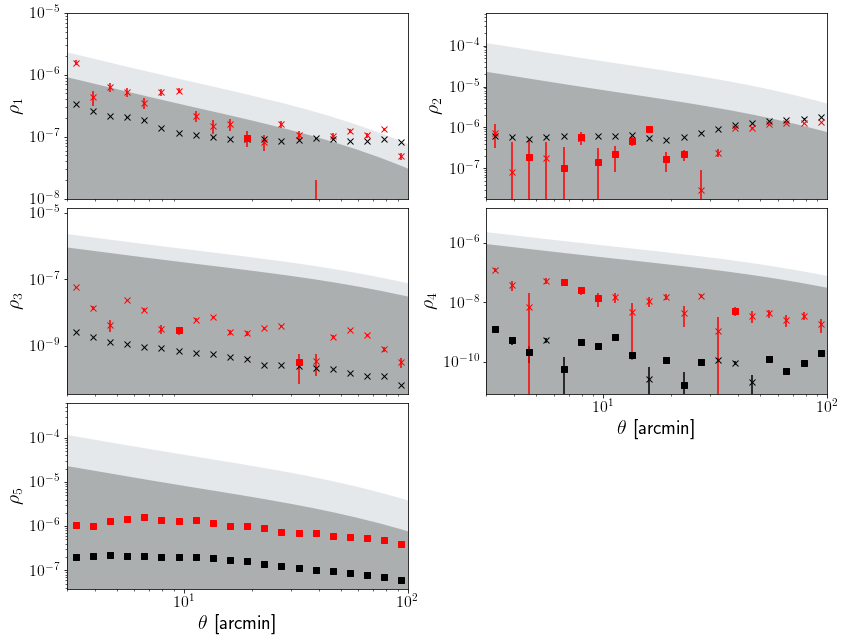

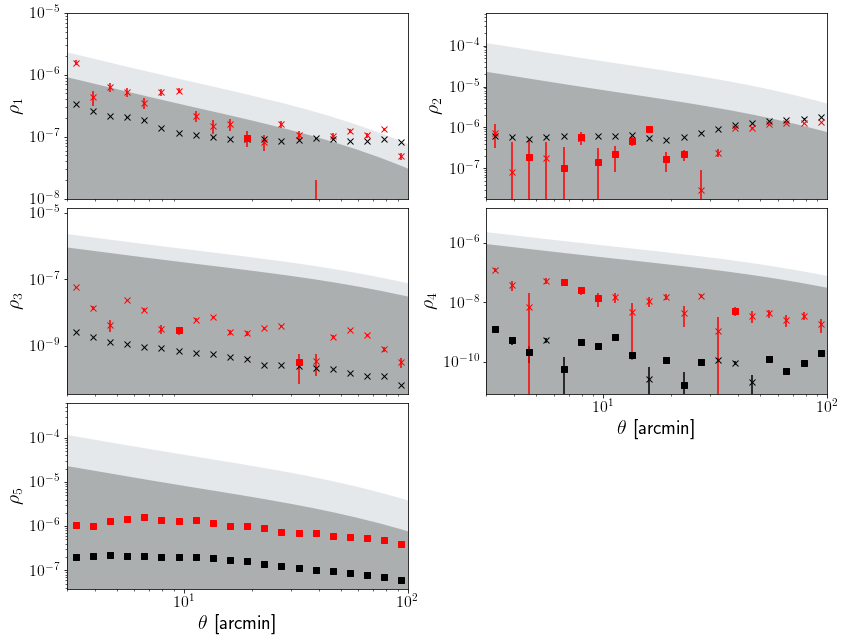

In [17]:
plt.close()

# requirement
rr,rho134,rho25=np.loadtxt(os.path.join(datDir,'rho_requirements.txt'),unpack=True,comments='#')
req=ascii.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=req['rr'];rho134n=req['rho134'];rho25n=req['rho25']
rr=rr*60
rrn=rrn*60

fig=plt.figure(figsize=(12,10))
fig.set_rasterized(True) 

# rho1
ax=fig.add_subplot(3,2,1)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)
plotGG(ax,rhoA['ra'],rhoA['dec'],rhoA['dg1'],rhoA['dg2'],'black',weights=None)
plotGG(ax,rhoB['ra'],rhoB['dec'],rhoB['dg1'],rhoB['dg2'],'red',weights=w2)
ax.set_xscale('log')
ax.set_xlim(0.05*60,100.)
ax.set_xticks(())
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_1$",fontsize=20.0)
ax.set_ylim(1e-8,1e-5)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,2)
ax.fill_between(rr,rho25,-rho25,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho25n,-rho25n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

plotGG(ax,rhoA['ra'],rhoA['dec'],rhoA['g1p'],rhoA['g2p'],'black',rhoA['dg1'],rhoA['dg2'])
plotGG(ax,rhoB['ra'],rhoB['dec'],rhoB['g1p'],rhoB['g2p'],'red',rhoB['dg1'],rhoB['dg2'])

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_ylabel(r"$\rho_2$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,3)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

plotGG(ax,rhoA['ra'],rhoA['dec'],rhoA['g1p']*rhoA['fdt'],rhoA['g2p']*rhoA['fdt'],'black')
plotGG(ax,rhoB['ra'],rhoB['dec'],rhoB['g1p']*rhoB['fdt'],rhoB['g2p']*rhoB['fdt'],'red',weights=w2)

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_ylabel(r"$\rho_3$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,4)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

plotGG(ax,rhoA['ra'],rhoA['dec'],rhoA['g1p']*rhoA['fdt'],rhoA['g2p']*rhoA['fdt'],'black',rhoA['dg1'],rhoA['dg2'])
plotGG(ax,rhoB['ra'],rhoB['dec'],rhoB['g1p']*rhoB['fdt'],rhoB['g2p']*rhoB['fdt'],'red',rhoB['dg1'],rhoB['dg2'],weights=w2)

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_4$",fontsize=20.0)
ax.set_xlabel(r"$\theta$ [arcmin]",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,5)
ax.fill_between(rr,rho25,-rho25,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho25n,-rho25n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

plotGG(ax,rhoA['ra'],rhoA['dec'],rhoA['g1p'],rhoA['g2p'],'black',rhoA['g1p']*rhoA['fdt'],rhoA['g2p']*rhoA['fdt'])
plotGG(ax,rhoB['ra'],rhoB['dec'],rhoB['g1p'],rhoB['g2p'],'red',rhoB['g1p']*rhoB['fdt'],rhoB['g2p']*rhoB['fdt'],weights=w2)

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_5$",fontsize=20.0)
ax.set_xlabel(r"$\theta$ [arcmin]",fontsize=20.0)
ax.set_rasterized(True)
fig.subplots_adjust(left=0.1,
                bottom=0.12, 
                right=0.98, 
                top=0.92, 
                wspace=0.23, 
                hspace=0.05)
fig

In [18]:
fig.savefig(os.path.join(pltDir,'psf_rho_tests_%s_reweight.eps' %pend),rasterized=True,dpi=200)
fig.savefig(os.path.join(pltDir,'psf_rho_tests_%s_reweight.png' %pend))

(0.05, 2.0)

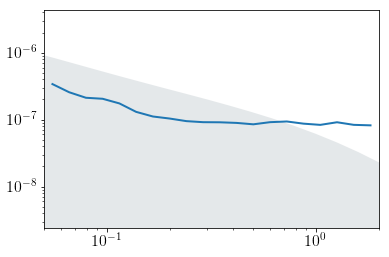

In [171]:
cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=2.,sep_units='degree')
catT1=   treecorr.Catalog(g1=dg1_1,g2=-dg2_1,\
                            ra=cat1['i_ra'],dec=cat1['i_dec'],\
                            ra_units='deg',dec_units='deg') 
cor.process(catT1,catT1)
plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
plt.errorbar(cor.rnom,cor.xip,or.varxi/np.sqrt(2.))
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.05,2.0)

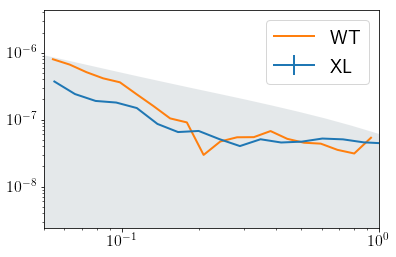

In [210]:
cor.clear()
data=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_others/WIDE12H_star.fits')
data=data[data['i_calib_psf_used']]
dg1_1,dg2_1=get_dg12(data)
cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=2.,sep_units='degree')
catT1=   treecorr.Catalog(g1=dg1_1,g2=-dg2_1,\
                            ra=data['i_ra'],dec=data['i_dec'],\
                            ra_units='deg',dec_units='deg') 
cor.process(catT1,catT1)
plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
plt.errorbar(cor.rnom,cor.xip,cor.varxi/np.sqrt(2.),label='XL')
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.05,1.0)

rho1=np.zeros(20)
for fieldname in ['WIDE12H']:
    rho1+=dataDictT[fieldname]['rho1']/1e6
plt.plot(dataDictT['XMM']['r'],rho1,'-',label='WT')
plt.legend()


[  3565.   4842.   6469.   8671.  11317.  14879.  19430.  25969.  33734.
  45254.  58812.  76994.  99177. 128721. 165065. 213099. 272644. 339456.
 420120. 511262.]
[  3565.   4842.   6469.   8671.  11316.  14883.  19426.  25973.  33733.
  45259.  58792.  77019.  99175. 128740. 165080. 213040. 272740. 339320.
 420100. 511240.]



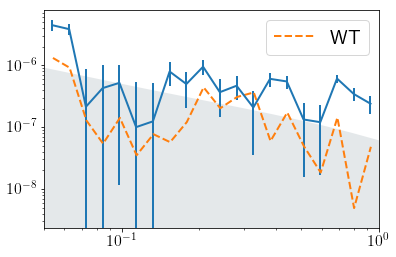

In [235]:
fieldname='XMM'
elinpname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/%s_sm-S19A-g15_nonpsfstars.fits'  %(fieldname)
data=pyfits.getdata(elinpname)
dg1_1,dg2_1=get_dg12(data)

cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.,sep_units='degree')
catT1=   treecorr.Catalog(g1=dg1_1,g2=-dg2_1,\
                            ra=data['i_ra'],dec=data['i_dec'],\
                            ra_units='deg',dec_units='deg') 

cor.process(catT1)
print(cor.npairs)
plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
plt.errorbar(cor.rnom,np.abs(cor.xip),np.sqrt(cor.varxi/2.))
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.05,1.0)


rho1=np.zeros(20)
ppp=np.zeros(20)
for fieldname in [fieldname]:
    rho1+=dataDictF[fieldname]['rho1']*dataDictF[fieldname]['npair']
    ppp+=dataDictF[fieldname]['npair']
print(ppp)
print()
plt.plot(dataDictF['XMM']['r'],np.abs(rho1)/1e6/ppp,'--',label='WT')
plt.legend()

[  3565.   4842.   6469.   8671.  11317.  14879.  19430.  25969.  33734.
  45254.  58812.  76994.  99177. 128721. 165065. 213099. 272644. 339456.
 420120. 511262.]
[   9133.   12235.   15929.   21331.   27813.   36793.   48507.   65144.
   85773.  115689.  153262.  203715.  271453.  356216.  473870.  627752.
  831618. 1092172. 1432848. 1862285.]
[   5960.    8014.   10585.   14044.   18280.   24442.   32075.   43493.
   57251.   76752.  102542.  136320.  181509.  240290.  320839.  424508.
  560250.  729312.  951061. 1230205.]
[  1806.   2304.   2972.   4051.   5462.   7201.   9303.  12451.  16835.
  22438.  29760.  39643.  52414.  70182.  92290. 120807. 160176. 210793.
 272310. 349472.]
[   5655.    7596.    9773.   13101.   17369.   23054.   30160.   40716.
   54404.   71830.   95824.  127121.  168581.  224122.  296571.  394705.
  516937.  676969.  877907. 1129852.]
[  1255.   1644.   2150.   2908.   3896.   5165.   6854.   8941.  11907.
  15991.  20470.  27165.  36415.  46833.  59758

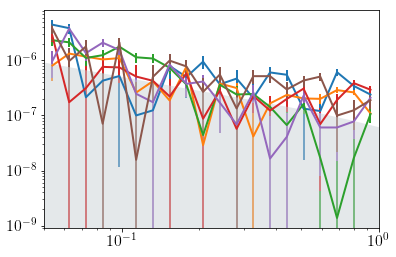

In [243]:
for fieldname in catutil.field_names:
    elinpname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/%s_sm-S19A-g15_nonpsfstars.fits'  %(fieldname)
    data=pyfits.getdata(elinpname)
    dg1_1,dg2_1=get_dg12(data)
    cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.,sep_units='degree')
    catT1=   treecorr.Catalog(g1=dg1_1,g2=-dg2_1,\
                                ra=data['i_ra'],dec=data['i_dec'],\
                                ra_units='deg',dec_units='deg') 

    cor.process(catT1)
    print(cor.npairs)
    plt.errorbar(cor.rnom,np.abs(cor.xip),np.sqrt(cor.varxi/2.),label=fieldname)
    
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.05,1.0)

plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
#plt.legend()

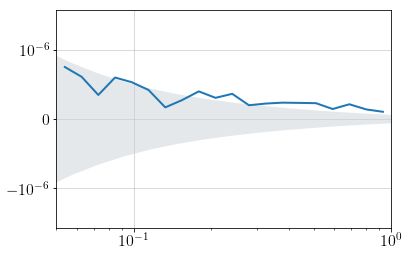

In [265]:
import gc
ccc=np.zeros(20)
ppp=np.zeros(20)
for fieldname in catutil.field_names:
    fname='/work/xiangchong.li/work/galSim-HSC/database/s16/S16AStandardV2/field/%s_stars.fits'  %(fieldname)
    data=pyfits.getdata(fname)
    data=data[~data['icalib_psf_used']]
    dg1_1,dg2_1=get2_dg12(data)
    cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.,sep_units='degree')
    catT1=   treecorr.Catalog(g1=dg1_1,g2=-dg2_1,\
                                ra=data['ira'],dec=data['idec'],\
                                ra_units='deg',dec_units='deg') 
    cor.process(catT1)
    ccc=ccc+cor.xip*cor.npairs
    ppp=ppp+cor.npairs
    rn=cor.rnom
    cor.clear()
    del data,cor,dg1_1,dg2_1
    gc.collect()
    
    #print(cor.npairs)
#plt.errorbar(rn,np.abs(ccc),np.sqrt(cor.varxi/2.),label=fieldname)
plt.errorbar(rn,ccc/ppp,label=fieldname)
    
plt.yscale('symlog',linthreshy=1e-6)
plt.xscale('log')
plt.xlim(0.05,1.0)

plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
plt.grid()
#plt.legend()

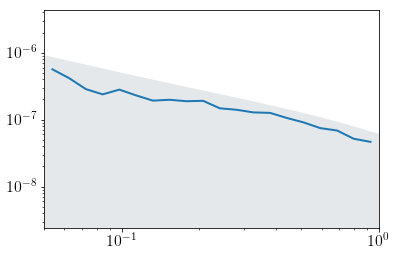

In [259]:
import gc
ccc=np.zeros(20)
ppp=np.zeros(20)
for fieldname in catutil.field_names:
    fname='/work/xiangchong.li/work/galSim-HSC/database/s16/S16AStandardV2/field/%s_stars.fits'  %(fieldname)
    data=pyfits.getdata(fname)
    data=data[data['icalib_psf_used']]
    dg1_1,dg2_1=get2_dg12(data)
    cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.,sep_units='degree')
    catT1=   treecorr.Catalog(g1=dg1_1,g2=-dg2_1,\
                                ra=data['ira'],dec=data['idec'],\
                                ra_units='deg',dec_units='deg') 
    cor.process(catT1)
    ccc=ccc+cor.xip*cor.npairs
    ppp=ppp+cor.npairs
    rn=cor.rnom
    cor.clear()
    del data,cor,dg1_1,dg2_1
    gc.collect()
    
    #print(cor.npairs)
#plt.errorbar(rn,np.abs(ccc),np.sqrt(cor.varxi/2.),label=fieldname)
plt.errorbar(rn,ccc/ppp,label=fieldname)
    
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.05,1.0)

plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
#plt.legend()

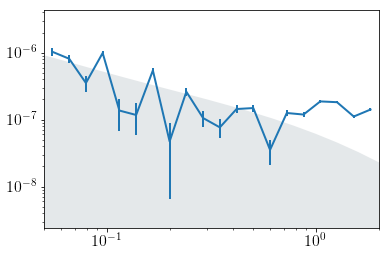

In [217]:
cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=2.,sep_units='degree')
cor.clear()
catT2=   treecorr.Catalog(g1=dg1_2,g2=-dg2_2,\
                            ra=cat2['i_ra'],dec=cat2['i_dec'],\
                            ra_units='deg',dec_units='deg')
cor.process(catT2,catT2)
plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
plt.errorbar(cor.rnom,cor.xip,np.sqrt(cor.varxi/2.))
plt.xlim(0.05,2.0)
plt.xscale('log')
plt.yscale('log')

In [216]:
np.sqrt(cor.varxi)

array([4.08136480e-07, 3.42489512e-07, 2.88869431e-07, 2.43766264e-07,
       2.04138162e-07, 1.72439014e-07, 1.44167611e-07, 1.20778734e-07,
       1.01002111e-07, 8.45883433e-08, 7.11633071e-08, 5.96824435e-08,
       5.00944051e-08, 4.22769984e-08, 3.59498323e-08, 3.05663210e-08,
       2.61946417e-08, 2.25018770e-08, 1.96092534e-08, 1.72651547e-08])

In [82]:
dataDictT={}
dataDictF={}
cnames=['r','rho1','rho1err','rho2','rho2err','rho3','rho3err','rho4','rho4err','rho5','rho5err']
for fieldname in utilities.field_names:
    dataDictT.update({fieldname:ascii.read(os.path.join(datDir,'%s_rhos_true.dat' %fieldname),names=cnames)})
    dataDictF.update({fieldname:ascii.read(os.path.join(datDir,'%s_rhos_false.dat' %fieldname),names=cnames)})

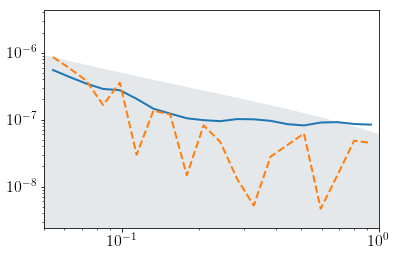

In [160]:
rho1=np.zeros(20)
for fieldname in utilities.field_names:
    rho1+=dataDictT[fieldname]['rho1']/6e6
plt.plot(dataDictT['XMM']['r'],rho1,'-',label='True')
plt.fill_between(rrn,yy+(rho134n),yy-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)

rho1=np.zeros(20)
for fieldname in utilities.field_names:
    rho1+=dataDictF[fieldname]['rho1']/6e6
plt.plot(dataDictF['XMM']['r'],np.abs(rho1),'--',label='false')

plt.xlim(0.05,1.0)
plt.xscale('log')
plt.yscale('log')

In [17]:
dataDictT={}
dataDictF={}
cnames=['r','rho1','rho1err','npair']
for fieldname in utilities.field_names:
    dataDictT.update({fieldname:ascii.read(os.path.join(datDirR,'%s_rhos_true.dat' %fieldname),names=cnames)})
    dataDictF.update({fieldname:ascii.read(os.path.join(datDirR,'%s_rhos_false.dat' %fieldname),names=cnames)})

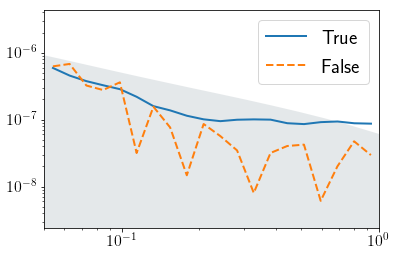

In [20]:
rho1=np.zeros(20)
ppp=np.zeros(20)
for fieldname in utilities.field_names:
    rho1+=dataDictT[fieldname]['rho1']*dataDictT[fieldname]['npair']
    ppp+=dataDictT[fieldname]['npair']
plt.plot(dataDictT['XMM']['r'],rho1/1e6/ppp,'-',label='True')

rho1=np.zeros(20)
ppp=np.zeros(20)
for fieldname in utilities.field_names:
    rho1+=dataDictF[fieldname]['rho1']*dataDictF[fieldname]['npair']
    ppp+=dataDictF[fieldname]['npair']
plt.plot(dataDictF['XMM']['r'],np.abs(rho1)/1e6/ppp,'--',label='False')
plt.legend()

plt.fill_between(rrn,+(rho134n),-(rho134n),facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
plt.xlim(0.05,1.0)
plt.xscale('log')
plt.yscale('log')

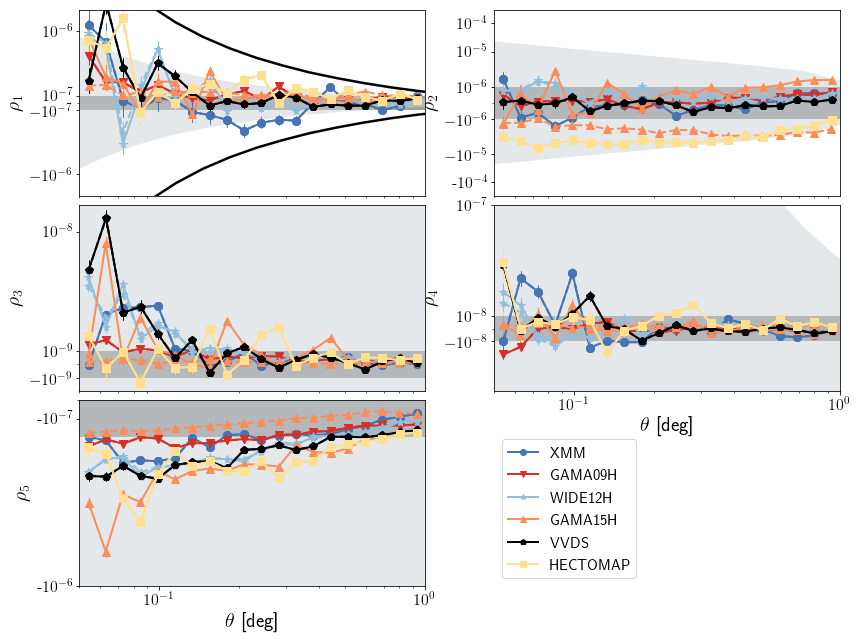

In [25]:
plt.close()
# load data
cnames=['r','rho1','rho1err','rho2','rho2err','rho3','rho3err','rho4','rho4err','rho5','rho5err']
dataDictT={}
dataDictF={}
for fieldname in utilities.field_names:
    dataDictT.update({fieldname:ascii.read(os.path.join(datDir,'%s_rhos_true.dat' %fieldname),names=cnames)})
    dataDictF.update({fieldname:ascii.read(os.path.join(datDir,'%s_rhos_false.dat' %fieldname),names=cnames)})

rr,rho134,rho25=np.loadtxt(os.path.join(datDir,'rho_requirements.txt'),unpack=True,comments='#')
data=ascii.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=data['rr'];rho134n=data['rho134'];rho25n=data['rho25']
xx=np.array([0.05,1])
yy=np.zeros(len(rr))
yr=yy*0.0+1e-6

fig=plt.figure(figsize=(12,10))
fig.set_rasterized(True) 

ax=fig.add_subplot(3,2,1)
ax.fill_between(rr,yy+yr*1e+5,yy-yr*1e+5,facecolor=fc2,linewidth=0.0,zorder=1,alpha=0.7)
ax.fill_between(rr,yy+(rho134n)*1e+6,yy-(rho134n)*1e+6,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
ax.plot(rr,yy+(rho134)*1e+6,'k-',linewidth=2.5)
ax.plot(rr,yy-(rho134)*1e+6,'k-',linewidth=2.5)
for fieldname in utilities.field_names:
    dT=dataDictT[fieldname]
    dF=dataDictF[fieldname]
    ax.errorbar(dT['r'],dT['rho1'],yerr=dT['rho1err'],fmt=pltutil.plot_fmt[fieldname]+'-',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0,label=fieldname)
    ax.errorbar(dF['r'],dF['rho1'],yerr=dF['rho1err'],fmt=pltutil.plot_fmt[fieldname]+'--',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0)
ax.set_xscale('log')
ax.set_xlim(0.05,1.0)
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_yscale('symlog',linthresy=0.1)
ax.set_yticks(np.array([-1,-0.1,0.1,1]))
ax.set_yticklabels((r'$-10^{-6}$',r'$-10^{-7}$',r'$10^{-7}$',r'$10^{-6}$'))
ax.set_ylim(-1.3,1.3)
ax.set_ylabel(r"$\rho_1$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,2)
ax.fill_between(rr,yy+yr*1e+6,yy-yr*1e+6,facecolor=fc2,linewidth=0.0,zorder=1,alpha=0.7)
ax.fill_between(rr,yy+(rho25n)*1e+6,yy-(rho25n)*1e+6,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
#ax.plot(rr,yy+(rho25)*1e+6,'k-',linewidth=2.5)
#ax.plot(rr,yy-(rho25)*1e+6,'k-',linewidth=2.5)
for fieldname in utilities.field_names:
    dT=dataDictT[fieldname]
    dF=dataDictF[fieldname]
    ax.errorbar(dT['r'],dT['rho2'],yerr=dT['rho2err'],fmt=pltutil.plot_fmt[fieldname]+'-',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0,label=fieldname)
    ax.errorbar(dF['r'],dF['rho2'],yerr=dF['rho2err'],fmt=pltutil.plot_fmt[fieldname]+'--',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0)
ax.set_xlim(0.05,1.0)
ax.set_xscale('log')
ax.set_yscale('symlog',linthresy=1.0)
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_yticks(np.array([-1000,-100,-10,-1.0,1,10,100,1000]))
ax.set_ylim(-300.0,300.0)
ax.set_yticklabels(('-$10^{-3}$','-$10^{-4}$','$-10^{-5}$','$-10^{-6}$',\
      '$10^{-6}$','$10^{-5}$','$10^{-4}$','$10^{-3}$'))
ax.set_ylabel(r"$\rho_2$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,3)
ax.fill_between(rr,yy+yr*1e+3,yy-yr*1e+3,facecolor=fc2,linewidth=0.0,zorder=1,alpha=0.7)
ax.fill_between(rr,yy+(rho134n)*1e+6,yy-(rho134n)*1e+6,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
#ax.plot(rr,yy+(rho134)*1e+6,'k-',linewidth=2.5)
#ax.plot(rr,yy-(rho134)*1e+6,'k-',linewidth=2.5)
for fieldname in utilities.field_names:
    dT=dataDictT[fieldname]
    dF=dataDictF[fieldname]
    ax.errorbar(dT['r'],dT['rho3'],yerr=dT['rho3err'],fmt=pltutil.plot_fmt[fieldname]+'-',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0,label=fieldname)
    ax.errorbar(dF['r'],dF['rho3'],yerr=dF['rho3err'],fmt=pltutil.plot_fmt[fieldname]+'--',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0)
ax.set_xlim(0.05,1.0)
ax.set_xscale('log')
ax.set_yscale('symlog',linthresy=0.001)
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_yticks(np.array([-0.001,0.001,0.01]))
ax.set_ylim(-0.002,0.012)
ax.set_yticklabels((r'$-10^{-9}$',r'$10^{-9}$',r'$10^{-8}$'))
ax.set_ylabel(r"$\rho_3$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,4)
ax.fill_between(rr,yy+yr*1e+4,yy-yr*1e+4,facecolor=fc2,linewidth=0.0,zorder=1,alpha=0.7)
ax.fill_between(rr,yy+(rho134n)*1e+6,yy-(rho134n)*1e+6,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
#ax.plot(rr,yy+(rho134)*1e+6,'k-',linewidth=2.5)
#ax.plot(rr,yy-(rho134)*1e+6,'k-',linewidth=2.5)
for fieldname in utilities.field_names:
    dT=dataDictT[fieldname]
    dF=dataDictF[fieldname]
    ax.errorbar(dT['r'],dT['rho4'],yerr=dT['rho4err'],fmt=pltutil.plot_fmt[fieldname]+'-',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0,label=fieldname)
    ax.errorbar(dF['r'],dF['rho4'],yerr=dF['rho4err'],fmt=pltutil.plot_fmt[fieldname]+'--',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0)
ax.set_xscale('log')
ax.set_xlim(0.05,1.0)
ax.set_yscale('symlog',linthresy=0.01)
ax.set_yticks(np.array([-0.1,-0.01,0.01,0.1]))
ax.set_yticklabels((r'$-10^{-7}$',r'$-10^{-8}$',r'$10^{-8}$',r'$10^{-7}$'))
ax.set_ylim(-0.05,0.1)
ax.set_ylabel(r"$\rho_4$",fontsize=20.0)
ax.set_xlabel(r"$\theta$ [deg]",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,5)
ax.fill_between(rr,yy+yr*2e+5,yy-yr*2e+5,facecolor=fc2,linewidth=0.0,zorder=1,alpha=0.7)
ax.fill_between(rr,yy+(rho25n)*1e+6,yy-(rho25n)*1e+6,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
#ax.plot(rr,yy+(rho25)*1e+6,'k-',linewidth=2.5)
#ax.plot(rr,yy-(rho25)*1e+6,'k-',linewidth=2.5)
for fieldname in utilities.field_names:
    dT=dataDictT[fieldname]
    dF=dataDictF[fieldname]
    ax.errorbar(dT['r'],dT['rho5'],yerr=dT['rho5err'],fmt=pltutil.plot_fmt[fieldname]+'-',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0,label=fieldname)
    ax.errorbar(dF['r'],dF['rho5'],yerr=dF['rho5err'],fmt=pltutil.plot_fmt[fieldname]+'--',\
                color=pltutil.plot_colors[fieldname],\
                ms=8,elinewidth=1.0)

ax.set_xlim(0.05,1.0)
ax.set_xscale('log')
ax.set_xlabel(r"$\theta$ [deg]",fontsize=20.0)

ax.set_yscale('symlog',linthresy=0.2)
ax.set_yticks(np.array([-1.0,-0.1,0.1]))
ax.set_yticklabels((r'-$10^{-6}$',r'-$10^{-7}$',r'$10^{-7}$'))
ax.set_ylim(-1.0,0.)
ax.set_ylabel(r"$\rho_5$",fontsize=20.0)
ax.set_rasterized(True)

ax        =   fig.add_subplot(3,2,6)
hdd       =   []
for fieldname in utilities.field_names:
    hdd.append(mlines.Line2D([], [], color=pltutil.plot_colors[fieldname],\
                             ls='-',marker=pltutil.plot_fmt[fieldname],label=fieldname))
ax.legend(handles=hdd,fontsize=15,loc='lower left')
ax.set_axis_off()
fig.subplots_adjust(left=0.1,
                bottom=0.12, 
                right=0.98, 
                top=0.92, 
                wspace=0.20, 
                hspace=0.05)